# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
from aitlas.datasets import DstlDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import os
import matplotlib.pyplot as plt

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir": "./data/dstl/dstl-satellite-imagery-feature-detection"
}
dataset = DstlDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 25


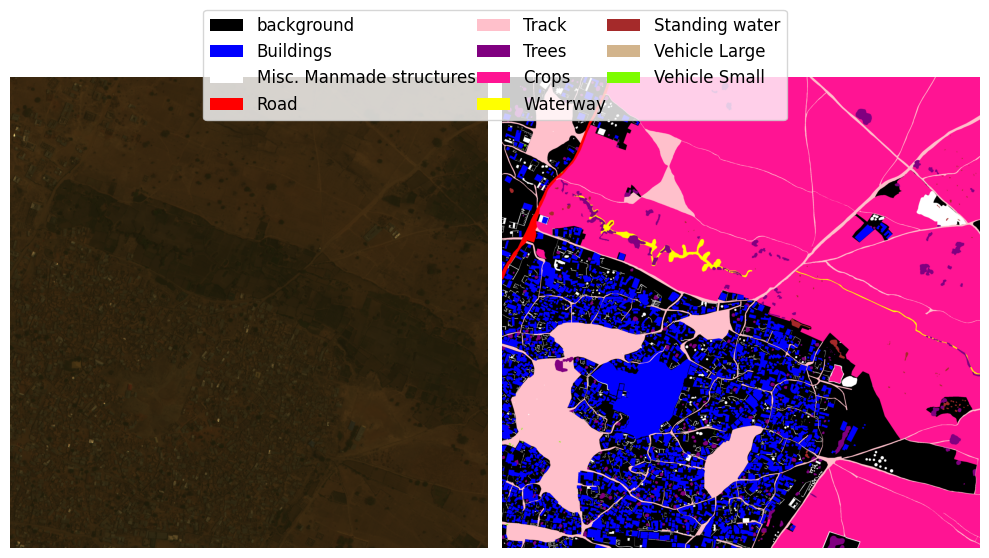

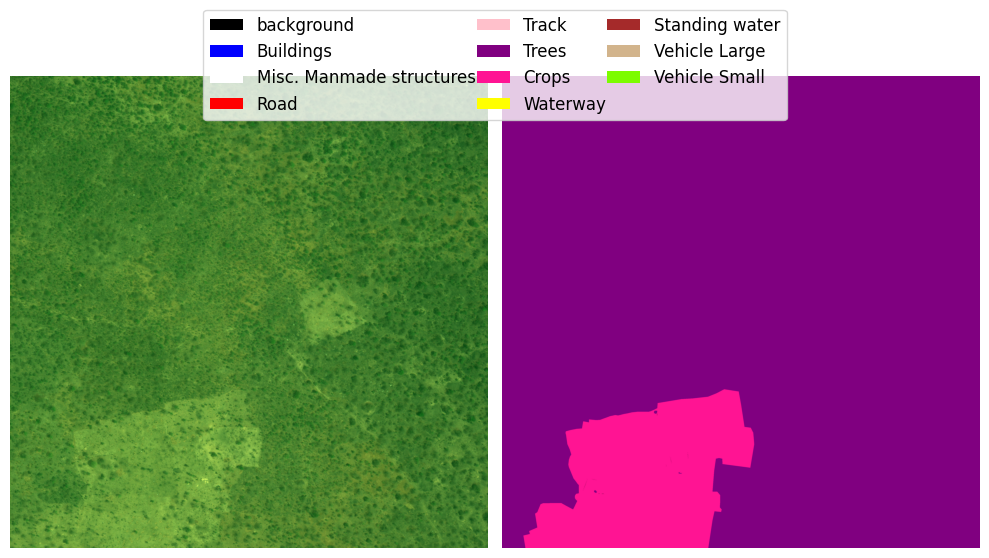

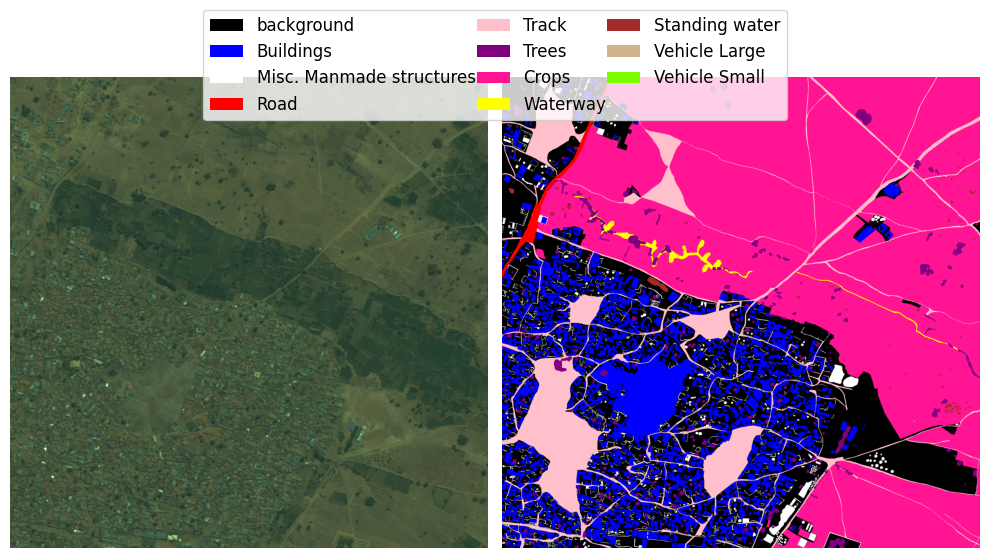

In [5]:
dataset.show_image(15);
dataset.show_image(23);
dataset.show_image(11);

In [20]:
dataset.data_distribution_table()

,Label,Number of pixels
0,Buildings,9331447.0
1,Misc. Manmade structures,2149112.0
2,Road,2664875.0
3,Track,14334166.0
4,Trees,63972795.0
5,Crops,79275827.0
6,Waterway,2177319.0
7,Standing water,482724.0
8,Vehicle Large,5248.0
9,Vehicle Small,43373.0


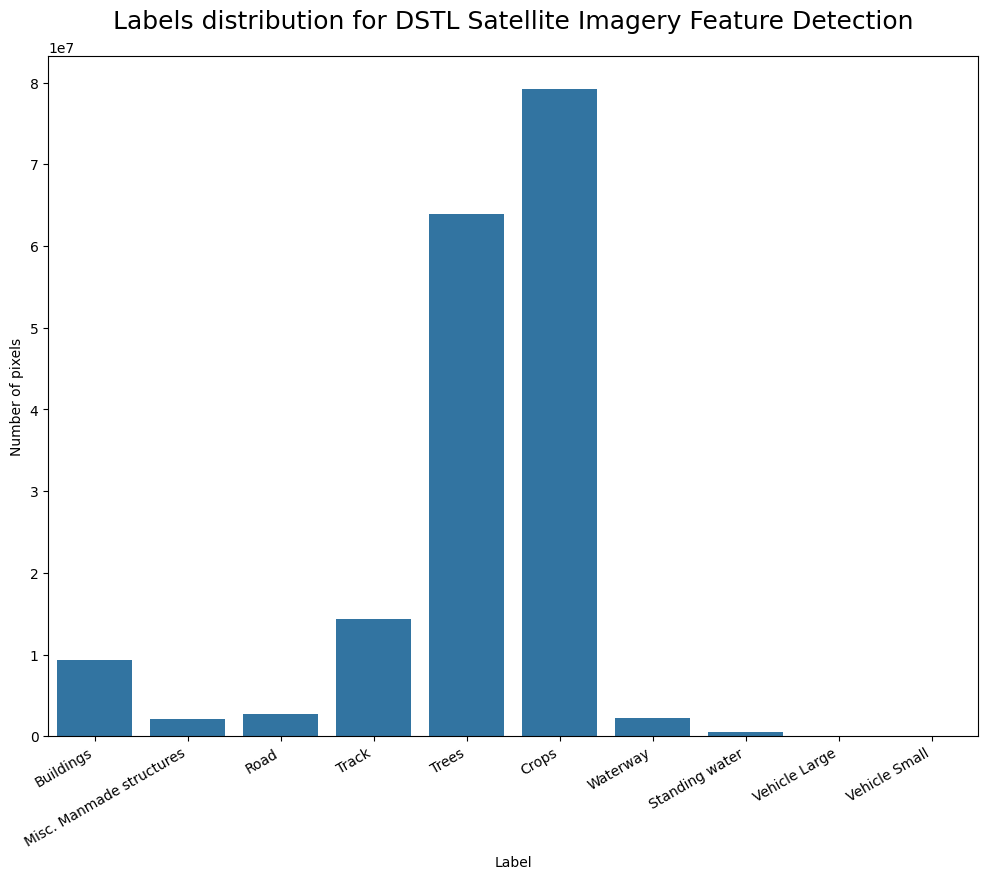

In [21]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 5,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/dstl/dstl-satellite-imagery-feature-detection",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = DstlDataset(train_dataset_config)
len(train_dataset)

25

## Create the model ##

In [ ]:
epochs = 20
model_directory = "./data/experiments/DSTL"
model_config = {
    "num_classes": 11, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-10-03 06:42:35,599 INFO Starting training.
training: 100%|██████████| 5/5 [03:37<00:00, 43.50s/it] 
2025-10-03 06:46:14,042 INFO epoch: 1, time: 218, loss:  0.83882
testing on train set: 100%|██████████| 5/5 [02:57<00:00, 35.49s/it]
2025-10-03 06:49:13,759 INFO IOU:0.05966843551767055, IOU mean:0.06387197970512153, IOU per Class:[0.28334656 0.00533956 0.00208435 0.00414494 0.0457553  0.20330243
 0.15333581 0.00438377 0.00089905 0.         0.        ]
training: 100%|██████████| 5/5 [03:05<00:00, 37.14s/it]
2025-10-03 06:52:19,466 INFO epoch: 2, time: 186, loss:  0.81991
testing on train set: 100%|██████████| 5/5 [02:42<00:00, 32.48s/it]
2025-10-03 06:55:01,900 INFO IOU:0.06746724683468394, IOU mean:0.05678418103077434, IOU per Class:[0.25170037 0.00140742 0.00109063 0.00391119 0.04018324 0.17134944
 0.15278631 0.00128106 0.00091633 0.         0.        ]
training: 100%|██████████| 5/5 [04:29<00:00, 53.87s/it] 
2025-10-03 06:59:31,247 INFO epoch: 3, time: 270, loss:  0.80127
testing

0.6929712414741516

## Predictions ##

2025-10-07 07:16:56,717 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/DSTL/checkpoint.pth.tar
2025-10-07 07:16:57,060 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/DSTL/checkpoint.pth.tar at epoch 21


425


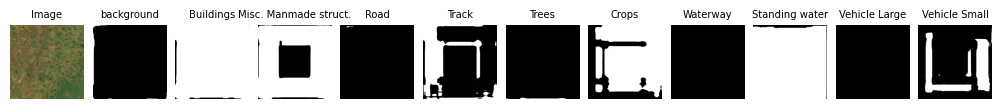

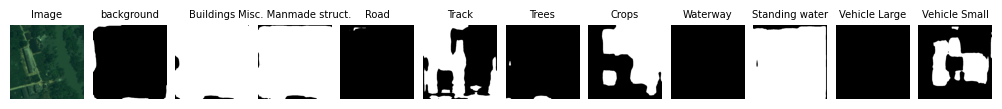

In [ ]:
model_path = "./data/experiments/DSTL/checkpoint.pth.tar"
labels = ["background",
        "Buildings",
        "Misc. Manmade struct.",
        "Road",
        "Track",
        "Trees",
        "Crops",
        "Waterway",
        "Standing water",
        "Vehicle Large",
        "Vehicle Small"]
transform = MinMaxNormTranspose()
plt.rcParams.update({'font.size': 6})
model.load_model(model_path)

test_images = []
images_path = './data/dstl/dstl-satellite-imagery-feature-detection/three_band/'
train_annotations_path = './data/dstl/dstl-satellite-imagery-feature-detection/train_geojson_v3/'
for image in os.listdir(images_path):
    if image[: -4] not in os.listdir(train_annotations_path):
        test_images.append(image)
print(len(test_images))

image = image_loader('./data/dstl/dstl-satellite-imagery-feature-detection/three_band/'+test_images[10])[:,:1024,:1024]
image = image.transpose(1, 2, 0)
img_min, img_max = image.min(), image.max()
img_norm = (image - img_min) / (img_max - img_min)
fig = model.predict_masks(img_norm, labels, transform)

image = image_loader('./data/dstl/dstl-satellite-imagery-feature-detection/three_band/'+test_images[100])[:,:512,:512]
image = image.transpose(1, 2, 0)
img_min, img_max = image.min(), image.max()
img_norm = (image - img_min) / (img_max - img_min)
fig = model.predict_masks(img_norm, labels, transform)